# Task 3: Test-time compute
Run the short cells in order. Kaggle computes and saves the fixed protocol. A local **Run All** reads the completed `Task_3/results/` at each step and displays the Kaggle metrics, tables, and figures without scoring answers or generating model responses.

## Common setup
On Kaggle, attach the complete `Task_3/` dataset and import this notebook. Locally, open this file with the `ATML` Conda kernel and the included compact `results/` evidence, or copy the completed Kaggle results into `Task_3/`. Run all cells; the notebook detects the local runtime and replays saved evidence.

### Runtime and code staging

In [1]:
from pathlib import Path
import os, shutil, sys, time
NOTEBOOK_STARTED = time.time()
IN_KAGGLE = Path("/kaggle/working").is_dir()
if IN_KAGGLE:
    sources = [p.parent.parent for p in Path("/kaggle/input").rglob("base.yaml")
               if p.parent.name == "configs"
               and (p.parent.parent / "input_data" / "README.MD").is_file()]
    if len(sources) != 1:
        raise FileNotFoundError(f"Attach exactly one Task_3 code dataset. Found: {sources}")
    shutil.copytree(sources[0], Path("/kaggle/working/Task_3"), dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns("input_data", "results"))
    TASK_ROOT = Path("/kaggle/working/Task_3")
else:
    TASK_ROOT = Path.cwd() if (Path.cwd() / "configs/base.yaml").is_file() else Path.cwd() / "Task_3"
if not (TASK_ROOT / "configs/base.yaml").is_file():
    raise FileNotFoundError(f"Task_3 code folder not found: {TASK_ROOT}")
os.chdir(TASK_ROOT)
sys.path.insert(0, str(TASK_ROOT))
print("Task root:", TASK_ROOT, "| Kaggle compute:", IN_KAGGLE)

Task root: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_3\Task_3 | Kaggle compute: False


### Kaggle dependencies

In [2]:
if IN_KAGGLE:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r",
                           str(TASK_ROOT / "requirements-kaggle.txt")])
else:
    print("Local replay: dependency installation skipped.")

Local replay: dependency installation skipped.


### Restore previous output and establish paths

In [3]:
if IN_KAGGLE:
    from cloud.kaggle import stage_kaggle
    TASK_ROOT, DATA_INPUT = stage_kaggle()
else:
    DATA_INPUT = None
from common.shared import fingerprint, paths, read_configuration, read_json, save_json, set_seed, source_fingerprint
if IN_KAGGLE:
    from data.archives import find_metadata, stage_archives
    DATA_INPUT = stage_archives(DATA_INPUT)
    HF_CACHE = Path("/kaggle/temp/Task_3_hf_cache")
    HF_CACHE.mkdir(parents=True, exist_ok=True)
    os.environ["HF_HOME"] = str(HF_CACHE)
    os.environ["HF_HUB_CACHE"] = str(HF_CACHE / "hub")
    print("Writable Hugging Face cache:", HF_CACHE)
configuration = read_configuration()
storage = paths(configuration, data_override=DATA_INPUT)
results_root = storage["results"]
RUN_COMPUTE = IN_KAGGLE
if RUN_COMPUTE:
    set_seed(6304)
base_configuration_hash = fingerprint(configuration)
if RUN_COMPUTE:
    protocol_hash = source_fingerprint()
else:
    from cloud.kaggle import _protocol_hash
    protocol_hash = _protocol_hash(TASK_ROOT)
if RUN_COMPUTE:
    import hashlib
    metadata_sha256 = hashlib.sha256(find_metadata(DATA_INPUT).read_bytes()).hexdigest()
prior_manifest_path = results_root / "provenance" / "prior_run_manifest.json"
prior_manifest = read_json(prior_manifest_path) if prior_manifest_path.is_file() else None
if prior_manifest is not None and RUN_COMPUTE:
    if prior_manifest["base_configuration_hash"] != base_configuration_hash or prior_manifest["metadata_sha256"] != metadata_sha256:
        raise ValueError("Previous Task 3 results use different configuration or metadata.")
manifest_path = results_root / "metrics" / "run_manifest.json"
if manifest_path.is_file():
    manifest = read_json(manifest_path)
    if manifest["base_configuration_hash"] != base_configuration_hash:
        raise ValueError("Saved Task 3 results use a different configuration.")
    if manifest["protocol_hash"] != protocol_hash:
        if RUN_COMPUTE:
            raise ValueError("Saved Task 3 results use a different scoring protocol.")
        print("Local replay: displaying saved results from an earlier source revision.")
    if RUN_COMPUTE and manifest.get("metadata_sha256") != metadata_sha256:
        raise ValueError("Saved Task 3 results use different MathVista metadata.")
else:
    manifest = {"base_configuration_hash": base_configuration_hash, "protocol_hash": protocol_hash,
                "metadata_sha256": metadata_sha256 if RUN_COMPUTE else None, "complete": False}
    if RUN_COMPUTE:
        save_json(manifest_path, manifest)
    else:
        raise FileNotFoundError(f"Copy the full Kaggle Task_3/results folder before local replay: {manifest_path}")
if not RUN_COMPUTE and not manifest["complete"]:
    raise RuntimeError("The copied Task 3 results are incomplete; resume the Kaggle version first.")
print("Mode:", "Kaggle compute" if RUN_COMPUTE else "local saved-result replay")
if not RUN_COMPUTE:
    print("Reading completed Kaggle results from:", results_root)

Mode: local saved-result replay
Reading completed Kaggle results from: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_3\Task_3\results


### Fixed revision, environment record, and session reserve

In [4]:
import importlib.metadata
if RUN_COMPUTE:
    from models.revision import resolve_revision
    revision = resolve_revision(configuration, DATA_INPUT)
    manifest["model_revision"] = revision
    versions = {name: importlib.metadata.version(name) for name in
                ("numpy", "pandas", "pyarrow", "math-verify", "transformers", "torch")}
    if prior_manifest is not None and (prior_manifest["model_revision"] != revision or prior_manifest["versions"] != versions):
        raise ValueError("Previous Task 3 results use a different model revision or package versions.")
    if "versions" in manifest and manifest["versions"] != versions:
        raise ValueError("Saved Task 3 results use different package versions.")
    manifest["versions"] = versions
    save_json(manifest_path, manifest)
    session_deadline = NOTEBOOK_STARTED + 12 * 3600 - configuration["experiment"]["session_reserve_seconds"]
    import torch
    print("Pinned revision:", revision, "| CUDA devices:", torch.cuda.device_count())
    from data.answers import canonical_mathvista, equivalent
    if not equivalent(r"\frac{2}{4}", r"\frac{1}{2}", "math", {}):
        raise RuntimeError("MATH equivalence smoke check failed.")
    if canonical_mathvista("(B)", {"question_type": "multi_choice", "choices": ["97", "102"]}) != "B":
        raise RuntimeError("MathVista choice smoke check failed.")
    from models.live import _file_stem
    saved_questions_path = results_root / "progress" / "live_questions.json"
    saved_questions = read_json(saved_questions_path) if saved_questions_path.is_file() else []
    live_labels = ("single", "parallel_0", "parallel_1", "parallel_2", "revision")
    live_complete = len(saved_questions) == 50 and all((results_root / "progress" / "live_calls" /
        f"{_file_stem(question['sample_id'])}_{label}.json").is_file()
        for question in saved_questions for label in live_labels)
    if live_complete:
        print("Reusing all 250 saved live calls; model download and GPU smoke test skipped.")
    else:
        from huggingface_hub import snapshot_download
        model_snapshot = snapshot_download(repo_id=configuration["model"]["name"],
                                           revision=revision, cache_dir=os.environ["HF_HUB_CACHE"])
        from transformers import AutoConfig, AutoTokenizer
        AutoConfig.from_pretrained(configuration["model"]["name"], revision=revision,
                                   cache_dir=os.environ["HF_HUB_CACHE"])
        AutoTokenizer.from_pretrained(configuration["model"]["name"], revision=revision,
                                      cache_dir=os.environ["HF_HUB_CACHE"])
        from models.live import smoke_live_loading
        smoke_input_tokens = smoke_live_loading(configuration)
        print("Pinned model loaded and one-token GPU generation passed; prompt tokens:", smoke_input_tokens)
else:
    print("Saved model revision:", manifest["model_revision"])
    session_deadline = None

Saved model revision: aa8e72537993ba99e69dfaafa59ed015b17504d1


### Diagnostic checks before the long run

In [5]:
if RUN_COMPUTE:
    import unittest
    diagnostics = unittest.TestLoader().discover(str(TASK_ROOT / "tests"), pattern="test_*.py")
    diagnostic_result = unittest.TextTestRunner(verbosity=1).run(diagnostics)
    if not diagnostic_result.wasSuccessful():
        raise RuntimeError("Task 3 diagnostic checks failed before the offline analysis.")
    print("Task 3 protocol and figure checks passed.")

## Step 1: Establish the opportunity from repeated sampling
Load the two supplied exports, verify all joins and per-token arrays, save fixed question splits and ten candidate orders, then measure FirstAns and oracle coverage.

### Prepare MATH and MathVista candidate pools
MATH equivalence uses math-verify with a 15-second limit for candidate grouping and a 120-second limit for comparisons against gold answers. Pathological symbolic expressions can still time out; their counts remain visible in the audit. The labeling stage saves every five questions under `results/progress/` so a completed Kaggle version can resume those chunks.

In [6]:
if RUN_COMPUTE:
    from data.prepare import prepare_dataset
    from methods.offline import label_candidates
    math_candidates, math_split = prepare_dataset(storage["data"], configuration, results_root, "math")
    math_labeled = label_candidates(math_candidates, "math", results_root)
    import gc
    del math_candidates
    gc.collect()
    vision_candidates, vision_split = prepare_dataset(storage["data"], configuration, results_root, "mathvista")
    vision_labeled = label_candidates(vision_candidates, "mathvista", results_root)
    del vision_candidates
    gc.collect()
    print("Candidates:", len(math_labeled), len(vision_labeled))
else:
    math_split = read_json(results_root / "splits" / "math.json")
    vision_split = read_json(results_root / "splits" / "mathvista.json")
    for name, split in (("MATH", math_split), ("MathVista", vision_split)):
        quality = read_json(results_root / "metrics" / f"{name.lower()}_export_quality.json")
        print(name, "saved questions:", quality["questions"], "rollouts:", quality["rollouts"],
              "development/evaluation:", len(split["development"]), len(split["evaluation"]))

MATH saved questions: 1000 rollouts: 32000 development/evaluation: 200 800
MathVista saved questions: 1000 rollouts: 32000 development/evaluation: 200 800


### FirstAns, distinct answers, and oracle coverage

In [7]:
if RUN_COMPUTE:
    from methods.offline import evaluate_opportunity
    math_opportunity = evaluate_opportunity(math_labeled, math_split, configuration, "math", results_root)
    vision_opportunity = evaluate_opportunity(vision_labeled, vision_split, configuration, "mathvista", results_root)
    for name, frame in (("MATH", math_opportunity), ("MathVista", vision_opportunity)):
        heldout = frame.loc[frame["split"] == "evaluation"]
        print(name, heldout.groupby("budget")[["first_correct", "oracle", "distinct_answers"]].mean())
else:
    import pandas as pd
    from IPython.display import display
    for name in ("math", "mathvista"):
        fixed = pd.read_csv(results_root / "tables" / f"{name}_fixed.csv")
        print(name.upper(), "saved FirstAns and oracle opportunity by budget")
        display(fixed.loc[fixed["method"].isin(["first", "self_consistency"]),
                      ["budget", "method", "correct", "oracle", "distinct_answers", "questions"]])

MATH saved FirstAns and oracle opportunity by budget


,budget,method,correct,oracle,distinct_answers,questions
2,1,first,0.638625,0.638625,1.000000,800
4,1,self_consistency,0.638625,0.638625,1.000000,800
8,2,first,0.638625,0.721875,1.373375,800
10,2,self_consistency,0.638625,0.721875,1.373375,800
14,4,first,0.638625,0.783000,1.923125,800
16,4,self_consistency,0.689500,0.783000,1.923125,800
20,8,first,0.638625,0.833500,2.750375,800
22,8,self_consistency,0.713250,0.833500,2.750375,800
26,16,first,0.638625,0.871750,3.993875,800
28,16,self_consistency,0.725750,0.871750,3.993875,800


MATHVISTA saved FirstAns and oracle opportunity by budget


,budget,method,correct,oracle,distinct_answers,questions
2,1,first,0.536000,0.53600,1.000000,800
4,1,self_consistency,0.536000,0.53600,1.000000,800
14,2,first,0.536000,0.66625,1.425125,800
16,2,self_consistency,0.536000,0.66625,1.425125,800
26,4,first,0.536000,0.76225,1.918250,800
28,4,self_consistency,0.578000,0.76225,1.918250,800
38,8,first,0.536000,0.83075,2.499250,800
40,8,self_consistency,0.604500,0.83075,2.499250,800
50,16,first,0.536000,0.87175,3.175750,800
52,16,self_consistency,0.614750,0.87175,3.175750,800


## Step 2: Implement quality scoring and answer aggregation
Evaluate the prescribed confidence, vision, and consensus selectors at every nested candidate budget. Calibration uses only the current prefix.

### Score and select candidates

In [8]:
if RUN_COMPUTE:
    from methods.offline import evaluate_fixed_budgets
    math_fixed = evaluate_fixed_budgets(math_labeled, math_split, configuration, "math", results_root)
    vision_fixed = evaluate_fixed_budgets(vision_labeled, vision_split, configuration, "mathvista", results_root)
    print("Saved fixed-budget rows:", len(math_fixed), len(vision_fixed))
else:
    for name in ("math", "mathvista"):
        fixed = pd.read_csv(results_root / "tables" / f"{name}_fixed.csv")
        print(name.upper(), "saved selector comparison at budget 32")
        display(fixed.loc[fixed["budget"] == 32,
                      ["method", "correct", "oracle", "token_cost", "questions"]])

MATH saved selector comparison at budget 32


,method,correct,oracle,token_cost,questions
30,certainty_best,0.698750,0.905,21347.01750,800
31,certainty_rwc,0.747750,0.905,21347.01750,800
32,first,0.638625,0.905,666.69825,800
33,logp_best,0.633750,0.905,21347.01750,800
34,self_consistency,0.733000,0.905,21347.01750,800
35,shortest,0.616500,0.905,21347.01750,800


MATHVISTA saved selector comparison at budget 32


,method,correct,oracle,token_cost,questions
60,certainty_best,0.546250,0.895,8897.7575,800
61,certainty_rwc,0.625000,0.895,8897.7575,800
62,first,0.536000,0.895,278.9500,800
63,logp_best,0.481250,0.895,8897.7575,800
64,self_consistency,0.617125,0.895,8897.7575,800
65,shortest,0.538125,0.895,8897.7575,800
66,tokenwise_best,0.562500,0.895,8897.7575,800
67,tokenwise_rwc,0.626250,0.895,8897.7575,800
68,visconf_best,0.577500,0.895,8897.7575,800
69,visconf_rwc,0.631250,0.895,8897.7575,800


### Aggregate by question and bootstrap paired differences

In [9]:
if RUN_COMPUTE:
    from evaluation.summary import summarize_fixed
    math_fixed_summary, math_intervals = summarize_fixed(math_fixed, configuration, "math", results_root)
    vision_fixed_summary, vision_intervals = summarize_fixed(vision_fixed, configuration, "mathvista", results_root)
    print(math_fixed_summary.loc[math_fixed_summary["budget"] == 32,
                                 ["method", "correct", "oracle", "token_cost"]].to_string(index=False))
else:
    for name in ("math", "mathvista"):
        paired = pd.read_csv(results_root / "tables" / f"{name}_paired_intervals.csv")
        print(name.upper(), "saved paired accuracy differences at budget 32 (percentage points)")
        display(paired.loc[paired["budget"] == 32])

MATH saved paired accuracy differences at budget 32 (percentage points)


,dataset_name,budget,method,reference,difference_pp,ci_low_pp,ci_high_pp
45,math,32,certainty_best,first,6.0125,3.962500,7.950937
46,math,32,certainty_best,self_consistency,-3.4250,-5.775313,-1.125000
47,math,32,certainty_rwc,first,10.9125,9.162500,12.625625
48,math,32,certainty_rwc,self_consistency,1.4750,0.400000,2.587813
49,math,32,logp_best,first,-0.4875,-2.625000,1.563750
50,math,32,logp_best,self_consistency,-9.9250,-12.537812,-7.536875
51,math,32,self_consistency,first,9.4375,7.924687,10.987813
52,math,32,shortest,first,-2.2125,-4.450625,-0.135938
53,math,32,shortest,self_consistency,-11.6500,-14.288438,-9.199687


MATHVISTA saved paired accuracy differences at budget 32 (percentage points)


,dataset_name,budget,method,reference,difference_pp,ci_low_pp,ci_high_pp
105,mathvista,32,certainty_best,first,1.0250,-1.425938,3.537500
106,mathvista,32,certainty_best,self_consistency,-7.0875,-10.125312,-3.849688
107,mathvista,32,certainty_rwc,first,8.9000,6.811562,10.863750
108,mathvista,32,certainty_rwc,self_consistency,0.7875,-0.512500,2.162500
109,mathvista,32,logp_best,first,-5.4750,-7.887500,-3.150000
110,mathvista,32,logp_best,self_consistency,-13.5875,-16.625625,-10.524375
111,mathvista,32,self_consistency,first,8.1125,6.162187,9.951250
112,mathvista,32,shortest,first,0.2125,-2.375938,2.575625
113,mathvista,32,shortest,self_consistency,-7.9000,-10.975625,-4.924687
114,mathvista,32,tokenwise_best,first,2.6500,0.036250,4.962813


## Step 3: Investigate what the signals capture
Compare within-question score and length associations, top and bottom quartiles, confidence–vision correlation, and tokenwise fusion.

### Within-question and within-rollout diagnostics

In [10]:
if RUN_COMPUTE:
    from evaluation.signals import analyze_signals
    math_signals = analyze_signals(math_labeled, "math", results_root,
                                   math_split["evaluation"])
    vision_signals = analyze_signals(vision_labeled, "mathvista", results_root,
                                     vision_split["evaluation"],
                                     trajectory_ids=vision_split["evaluation"][:2])
    print("Saved signal diagnostic rows:", len(math_signals), len(vision_signals))
else:
    for name in ("math", "mathvista"):
        print(name.upper(), "saved score diagnostics")
        display(pd.read_csv(results_root / "tables" / f"{name}_signals.csv"))

MATH saved score diagnostics


,dataset_name,score,correctness_correlation,length_correlation,top_quartile_accuracy,bottom_quartile_accuracy,top_bottom_difference
0,math,certainty,0.198775,-0.161096,0.690156,0.570156,0.120000
1,math,length,-0.076418,1.000000,0.597969,0.642813,-0.044844
2,math,logp,0.135580,0.224510,0.672188,0.593125,0.079062


MATHVISTA saved score diagnostics


,dataset_name,score,correctness_correlation,length_correlation,top_quartile_accuracy,bottom_quartile_accuracy,top_bottom_difference
0,mathvista,certainty,0.047665,0.349333,0.549063,0.514219,0.034844
1,mathvista,confidence_vision_token_correlation,-0.210994,NaN,NaN,NaN,NaN
2,mathvista,length,-0.050391,1.000000,0.505000,0.545625,-0.040625
3,mathvista,logp,0.028683,0.328981,0.533125,0.517188,0.015938
4,mathvista,tokenwise,0.080468,-0.321803,0.561719,0.489531,0.072188
5,mathvista,visconf,0.088801,-0.275037,0.562500,0.488594,0.073906
6,mathvista,vision,0.041244,-0.685752,0.543125,0.505313,0.037812


### Compact signal tables

In [11]:
if RUN_COMPUTE:
    from evaluation.summary import summarize_signals
    math_signal_summary = summarize_signals(math_signals, "math", results_root)
    vision_signal_summary = summarize_signals(vision_signals, "mathvista", results_root)
    print(vision_signal_summary[["score", "correctness_correlation",
                                 "top_bottom_difference"]].to_string(index=False))
else:
    fusion = pd.read_parquet(results_root / "metrics" / "mathvista_fusion.parquet")
    trajectories = read_json(results_root / "metrics" / "mathvista_trajectories.json")
    print("Saved MathVista fusion diagnostics")
    display(fusion[["token_correlation", "fusion_covariance"]].mean().to_frame("mean"))
    print("Saved visual trajectories:", len(trajectories))

Saved MathVista fusion diagnostics


,mean
token_correlation,-0.210668
fusion_covariance,-0.002243


Saved visual trajectories: 2


## Step 4: Compare parallel sampling with sequential refinement
Use the fixed first 50 MATH evaluation questions. Run one 3072-token response, three independent 1024-token responses, and one 2048-token revision using the first parallel response. Save every call.

### Fix live question IDs and run the two GPU workers

In [12]:
if RUN_COMPUTE:
    from models.live import live_questions, launch_live
    live_question_file = live_questions(math_labeled, math_split, results_root)
    import gc
    del math_opportunity, vision_opportunity
    del math_labeled, vision_labeled
    gc.collect()
    live_frame = launch_live(live_question_file, configuration, results_root, session_deadline)
    print("Completed live questions:", live_frame["sample_id"].nunique() if len(live_frame) else 0, "/ 50")
else:
    live_questions_saved = read_json(results_root / "progress" / "live_questions.json")
    print("Saved live question IDs:", len(live_questions_saved), "| saved calls:",
          len(list((results_root / "progress" / "live_calls").glob("*.json"))))

Saved live question IDs: 50 | saved calls: 250


### Save live strategy costs and revision transitions

In [13]:
if RUN_COMPUTE and len(live_frame) == 150:
    from evaluation.summary import summarize_live
    live_summary, revision_transitions = summarize_live(live_frame, results_root)
    print(live_summary.to_string(index=False))
    print(revision_transitions)
elif RUN_COMPUTE:
    print("Live calls were saved. Finish the remaining questions in the next Kaggle version.")
else:
    print("Saved 50-question live strategy comparison")
    display(pd.read_csv(results_root / "tables" / "live_strategies.csv"))
    display(pd.read_csv(results_root / "tables" / "live_paired_intervals.csv"))

Saved 50-question live strategy comparison


,strategy,accuracy,input_tokens,output_tokens,runtime_seconds,extraction_rate,truncation_rate,peak_gpu_gb,questions
0,parallel,0.58,325.14,1834.94,87.665298,0.86,0.26,5.946849,50
1,refinement,0.56,869.48,1209.84,58.707610,1.00,0.12,6.173303,50
2,single,0.72,108.38,736.30,35.751876,0.96,0.04,6.084351,50


,method,reference,difference_pp,ci_low_pp,ci_high_pp
0,parallel,single,-14.0,-26.0,-2.0
1,refinement,single,-16.0,-30.0,-2.0
2,refinement,parallel,-2.0,-10.0,6.0


## Step 5: Implement adaptive sampling
Tune agreement and quality-aware stopping on each development set only, freeze thresholds, then score the held-out evaluation sets.

### Prefix evidence at candidate counts 4, 8, 16, and 32

In [14]:
if RUN_COMPUTE:
    import pandas as pd
    math_labeled = pd.read_parquet(results_root / "predictions" / "math_labeled.parquet")
    vision_labeled = pd.read_parquet(results_root / "predictions" / "mathvista_labeled.parquet")
    from methods.adaptive import build_states
    math_states = build_states(math_labeled, math_split, configuration, "math", results_root)
    vision_states = build_states(vision_labeled, vision_split, configuration, "mathvista", results_root)
    print("Saved adaptive prefix states:", len(math_states), len(vision_states))
else:
    from pyarrow.parquet import ParquetFile
    for name in ("math", "mathvista"):
        count = ParquetFile(results_root / "predictions" / f"{name}_adaptive_states.parquet").metadata.num_rows
        print(name.upper(), "saved adaptive prefix states:", count)

MATH saved adaptive prefix states: 40000


MATHVISTA saved adaptive prefix states: 40000


### Development threshold selection and held-out evaluation

In [15]:
if RUN_COMPUTE:
    from methods.adaptive import select_thresholds, evaluate_adaptive
    math_thresholds = select_thresholds(math_states, configuration, "math", results_root)
    vision_thresholds = select_thresholds(vision_states, configuration, "mathvista", results_root)
    math_adaptive = evaluate_adaptive(math_states, math_thresholds, "math", results_root)
    vision_adaptive = evaluate_adaptive(vision_states, vision_thresholds, "mathvista", results_root)
    print("MATH:", math_thresholds, "\nMathVista:", vision_thresholds)
else:
    for name in ("math", "mathvista"):
        print(name.upper(), "saved development thresholds:",
              read_json(results_root / "metrics" / f"{name}_chosen_thresholds.json"))
        display(pd.read_csv(results_root / "tables" / f"{name}_adaptive.csv"))

MATH saved development thresholds: {'baseline_accuracy': 0.815, 'minimum_accuracy': 0.8049999999999999, 'agreement': {'family': 'agreement', 'tau': 0.5, 'gamma': None, 'accuracy': 0.809, 'mean_tokens': 4884.1985}, 'quality': {'family': 'quality', 'tau': 0.5, 'gamma': 0.0, 'accuracy': 0.8125, 'mean_tokens': 5260.075}}


,dataset_name,policy,correct,token_cost,count,questions
0,math,agreement,0.723000,6750.029875,7.9380,800
1,math,always32,0.733000,21347.017500,32.0000,800
2,math,quality,0.727125,7622.621625,8.9165,800


MATHVISTA saved development thresholds: {'baseline_accuracy': 0.6425, 'minimum_accuracy': 0.6325, 'agreement': {'family': 'agreement', 'tau': 0.625, 'gamma': None, 'accuracy': 0.635, 'mean_tokens': 5285.1855}, 'quality': {'family': 'quality', 'tau': 0.5, 'gamma': 0.25, 'accuracy': 0.6325, 'mean_tokens': 4683.999}}


,dataset_name,policy,correct,token_cost,count,questions
0,mathvista,agreement,0.619500,4655.168125,13.7975,800
1,mathvista,always32,0.617125,8897.757500,32.0000,800
2,mathvista,quality,0.617750,4203.773625,12.8265,800


## Step 6: Analyze compute allocation and failure cases
Compare generated-token costs with accuracy and choose aligned examples using fixed rules.

### Adaptive cost and stopping distributions

In [16]:
if RUN_COMPUTE:
    from evaluation.summary import summarize_adaptive
    math_adaptive_summary, math_stops = summarize_adaptive(
        math_adaptive, math_thresholds, "math", results_root)
    vision_adaptive_summary, vision_stops = summarize_adaptive(
        vision_adaptive, vision_thresholds, "mathvista", results_root)
    from evaluation.summary import summarize_stopping_context
    math_stopping_context = summarize_stopping_context(
        math_adaptive, math_labeled, "math", results_root)
    vision_stopping_context = summarize_stopping_context(
        vision_adaptive, vision_labeled, "mathvista", results_root)
    print(math_adaptive_summary.to_string(index=False))
    print(vision_adaptive_summary.to_string(index=False))
else:
    for name in ("math", "mathvista"):
        print(name.upper(), "saved stopping counts and context")
        display(pd.read_csv(results_root / "tables" / f"{name}_stops.csv"))
        context = pd.read_csv(results_root / "tables" / f"{name}_stopping_context.csv")
        display(context.loc[context["policy"] == "quality"] )

MATH saved stopping counts and context


,dataset_name,policy,count,size,fraction
0,math,agreement,4,6596,0.824500
1,math,agreement,8,284,0.035500
2,math,agreement,16,62,0.007750
3,math,agreement,32,1058,0.132250
4,math,always32,32,8000,1.000000
5,math,quality,4,6161,0.770125
6,math,quality,8,442,0.055250
7,math,quality,16,97,0.012125
8,math,quality,32,1300,0.162500


,dataset_name,policy,count,full_pool_bin,questions,accuracy,mean_agreement,mean_full_pool_correct_fraction
18,math,quality,4,0-25%,191,0.062153,0.686459,0.075090
19,math,quality,4,25-50%,77,0.735084,0.650955,0.412664
20,math,quality,4,50-75%,74,0.960951,0.740238,0.667339
21,math,quality,4,75-100%,432,0.999530,0.963311,0.959453
22,math,quality,8,0-25%,82,0.033784,0.569257,0.082348
23,math,quality,8,25-50%,60,0.675214,0.551282,0.406250
24,math,quality,8,50-75%,60,0.981818,0.611364,0.648864
25,math,quality,8,75-100%,54,1.000000,0.708955,0.833489
26,math,quality,16,0-25%,28,0.000000,0.539286,0.070536
27,math,quality,16,25-50%,31,0.685714,0.523214,0.418750


MATHVISTA saved stopping counts and context


,dataset_name,policy,count,size,fraction
0,mathvista,agreement,4,4533,0.566625
1,mathvista,agreement,8,689,0.086125
2,mathvista,agreement,16,135,0.016875
3,mathvista,agreement,32,2643,0.330375
4,mathvista,always32,32,8000,1.000000
5,mathvista,quality,4,4625,0.578125
6,mathvista,quality,8,782,0.097750
7,mathvista,quality,16,320,0.040000
8,mathvista,quality,32,2273,0.284125


,dataset_name,policy,count,full_pool_bin,questions,accuracy,mean_agreement,mean_full_pool_correct_fraction
20,mathvista,quality,4,0-25%,161,0.067073,0.742759,0.102325
21,mathvista,quality,4,25-50%,132,0.536449,0.706542,0.401752
22,mathvista,quality,4,50-75%,132,0.935829,0.783422,0.648772
23,mathvista,quality,4,75-100%,292,0.999628,0.951229,0.932276
24,mathvista,quality,8,0-25%,79,0.040000,0.642500,0.117708
25,mathvista,quality,8,25-50%,99,0.597701,0.596264,0.403197
26,mathvista,quality,8,50-75%,117,0.950943,0.659434,0.633019
27,mathvista,quality,8,75-100%,108,1.000000,0.775907,0.863828
28,mathvista,quality,16,0-25%,42,0.000000,0.592803,0.114110
29,mathvista,quality,16,25-50%,54,0.607143,0.567708,0.406994


### Save reproducibly selected examples and completion status

In [17]:
if RUN_COMPUTE:
    from analysis.evidence import select_examples
    examples = select_examples({"math": math_labeled, "mathvista": vision_labeled},
                               {"math": math_fixed, "mathvista": vision_fixed},
                               {"math": math_adaptive, "mathvista": vision_adaptive},
                               results_root)
    required = [results_root / "tables" / name for name in
                ("math_fixed.csv", "mathvista_fixed.csv", "math_paired_intervals.csv",
                 "mathvista_paired_intervals.csv", "math_signals.csv",
                 "mathvista_signals.csv", "math_adaptive.csv", "mathvista_adaptive.csv",
                 "math_adaptive_paired_intervals.csv", "mathvista_adaptive_paired_intervals.csv",
                 "math_stops.csv", "mathvista_stops.csv",
                 "math_stopping_context.csv", "mathvista_stopping_context.csv",
                 "live_strategies.csv", "live_paired_intervals.csv")]
    required += [results_root / "metrics" / name for name in
                 ("math_export_quality.json", "mathvista_export_quality.json",
                  "mathvista_fusion.parquet", "mathvista_trajectories.json",
                  "math_chosen_thresholds.json", "mathvista_chosen_thresholds.json",
                  "revision_transitions.json", "qualitative_examples.json")]
    manifest["complete"] = len(live_frame) == 150 and all(path.is_file() for path in required)
    save_json(manifest_path, manifest)
    print("Full Task 3 result set complete:", manifest["complete"], "| examples:", list(examples))
else:
    examples = read_json(results_root / "metrics" / "qualitative_examples.json")
    print("Saved qualitative examples:")
    for name, example in examples.items():
        print(name, example["sample_id"], "-", example["rule"])
    print("Completed Kaggle run:", manifest["complete"])

Saved qualitative examples:
math_selection_disagreement test:1787 - Lexicographically first held-out question, order 0, N=32, with a correctness disagreement
math_premature_stop test:1157 - Lexicographically first held-out quality-aware early error recovered at fixed 32
mathvista_selection_disagreement 10 - Lexicographically first held-out question, order 0, N=32, with a correctness disagreement
mathvista_premature_stop 120 - Lexicographically first held-out quality-aware early error recovered at fixed 32
revision_changed_answer test:2177 - First sample ID whose extracted answer changed in revision
Completed Kaggle run: True


## Required evidence and research questions
These cells read saved results only. Run this notebook locally with the included compact `Task_3/results/` evidence to display the saved tables and PNG figures without model generation.

### Evidence gate

In [18]:
from IPython.display import display, Image
EVIDENCE_READY = bool(read_json(manifest_path)["complete"])
if not EVIDENCE_READY:
    print("Evidence awaits the remaining saved live calls; resume a Kaggle version.")
else:
    print("Saved-result evidence is ready. No model is loaded by the following cells.")
    print("MATH scorer: math-verify", manifest["versions"]["math-verify"])
    if not RUN_COMPUTE:
        required = [results_root / "figures" / name for name in
                    ("rq1_sampling.png", "rq1_failures.png", "rq2_signals.png",
                     "rq2_trajectories.png", "rq3_live.png", "rq4_adaptive.png", "rq5_cost.png")]
        missing = [str(path) for path in required if not path.is_file()]
        if missing:
            raise FileNotFoundError(f"Completed Kaggle figures are missing: {missing}")
        audit = read_json(results_root / "metrics" / "math_comparison_audit.json")
        print("Saved comparison audit: group/gold timeouts =",
              audit["group_timeouts"], audit["gold_timeouts"],
              "| grouping errors =", audit["group_errors"])

Saved-result evidence is ready. No model is loaded by the following cells.
MATH scorer: math-verify 0.8.0
Saved comparison audit: group/gold timeouts = 36 3 | grouping errors = 2


### RQ1: Exploration and selection
Show accuracy and oracle coverage as N grows, distinct answers, selection misses, and paired question-bootstrap intervals.

MATH FirstAns, self-consistency, and quality selection


,dataset_name,budget,method,correct,oracle,distinct_answers,token_cost,no_correct_candidate,selection_miss,questions
1,math,1,certainty_rwc,0.638625,0.638625,1.000000,666.698250,0.361375,0.000000,800
2,math,1,first,0.638625,0.638625,1.000000,666.698250,0.361375,0.000000,800
4,math,1,self_consistency,0.638625,0.638625,1.000000,666.698250,0.361375,0.000000,800
7,math,2,certainty_rwc,0.667750,0.721875,1.373375,1332.494500,0.278125,0.054125,800
8,math,2,first,0.638625,0.721875,1.373375,666.698250,0.278125,0.083250,800
10,math,2,self_consistency,0.638625,0.721875,1.373375,1332.494500,0.278125,0.083250,800
13,math,4,certainty_rwc,0.694125,0.783000,1.923125,2662.805625,0.217000,0.088875,800
14,math,4,first,0.638625,0.783000,1.923125,666.698250,0.217000,0.144375,800
16,math,4,self_consistency,0.689500,0.783000,1.923125,2662.805625,0.217000,0.093500,800
19,math,8,certainty_rwc,0.722875,0.833500,2.750375,5328.683875,0.166500,0.110625,800


MATHVISTA FirstAns, self-consistency, and quality selection


,dataset_name,budget,method,correct,oracle,distinct_answers,token_cost,no_correct_candidate,selection_miss,questions
2,mathvista,1,first,0.536000,0.53600,1.000000,278.950000,0.46400,0.000000,800
4,mathvista,1,self_consistency,0.536000,0.53600,1.000000,278.950000,0.46400,0.000000,800
9,mathvista,1,visconf_rwc,0.536000,0.53600,1.000000,278.950000,0.46400,0.000000,800
14,mathvista,2,first,0.536000,0.66625,1.425125,278.950000,0.33375,0.130250,800
16,mathvista,2,self_consistency,0.536000,0.66625,1.425125,559.169625,0.33375,0.130250,800
21,mathvista,2,visconf_rwc,0.546000,0.66625,1.425125,559.169625,0.33375,0.120250,800
26,mathvista,4,first,0.536000,0.76225,1.918250,278.950000,0.23775,0.226250,800
28,mathvista,4,self_consistency,0.578000,0.76225,1.918250,1109.712750,0.23775,0.184250,800
33,mathvista,4,visconf_rwc,0.574750,0.76225,1.918250,1109.712750,0.23775,0.187500,800
38,mathvista,8,first,0.536000,0.83075,2.499250,278.950000,0.16925,0.294750,800


MATH all methods at budget 32


,dataset_name,budget,method,correct,oracle,distinct_answers,token_cost,no_correct_candidate,selection_miss,questions
31,math,32,certainty_rwc,0.747750,0.905,5.905,21347.01750,0.095,0.157250,800
34,math,32,self_consistency,0.733000,0.905,5.905,21347.01750,0.095,0.172000,800
30,math,32,certainty_best,0.698750,0.905,5.905,21347.01750,0.095,0.206250,800
32,math,32,first,0.638625,0.905,5.905,666.69825,0.095,0.266375,800
33,math,32,logp_best,0.633750,0.905,5.905,21347.01750,0.095,0.271250,800
35,math,32,shortest,0.616500,0.905,5.905,21347.01750,0.095,0.288500,800


... (3 outputs left out)

,dataset_name,budget,method,reference,difference_pp,ci_low_pp,ci_high_pp
45,math,32,certainty_best,first,6.0125,3.962500,7.950937
46,math,32,certainty_best,self_consistency,-3.4250,-5.775313,-1.125000
47,math,32,certainty_rwc,first,10.9125,9.162500,12.625625
48,math,32,certainty_rwc,self_consistency,1.4750,0.400000,2.587813
49,math,32,logp_best,first,-0.4875,-2.625000,1.563750
50,math,32,logp_best,self_consistency,-9.9250,-12.537812,-7.536875
51,math,32,self_consistency,first,9.4375,7.924687,10.987813
52,math,32,shortest,first,-2.2125,-4.450625,-0.135938
53,math,32,shortest,self_consistency,-11.6500,-14.288438,-9.199687


MATHVISTA paired intervals at budget 32


,dataset_name,budget,method,reference,difference_pp,ci_low_pp,ci_high_pp
105,mathvista,32,certainty_best,first,1.0250,-1.425938,3.537500
106,mathvista,32,certainty_best,self_consistency,-7.0875,-10.125312,-3.849688
107,mathvista,32,certainty_rwc,first,8.9000,6.811562,10.863750
108,mathvista,32,certainty_rwc,self_consistency,0.7875,-0.512500,2.162500
109,mathvista,32,logp_best,first,-5.4750,-7.887500,-3.150000
110,mathvista,32,logp_best,self_consistency,-13.5875,-16.625625,-10.524375
111,mathvista,32,self_consistency,first,8.1125,6.162187,9.951250
112,mathvista,32,shortest,first,0.2125,-2.375938,2.575625
113,mathvista,32,shortest,self_consistency,-7.9000,-10.975625,-4.924687
114,mathvista,32,tokenwise_best,first,2.6500,0.036250,4.962813


Supplied export counts: {'math': {'questions': 1000, 'rollouts': 32000, 'retained_tokens': 20742094, 'capped_rollouts': 523, 'null_extractions': 521}, 'mathvista': {'questions': 1000, 'rollouts': 32000, 'retained_tokens': 8961703, 'capped_rollouts': 487, 'null_extractions': 3032}}


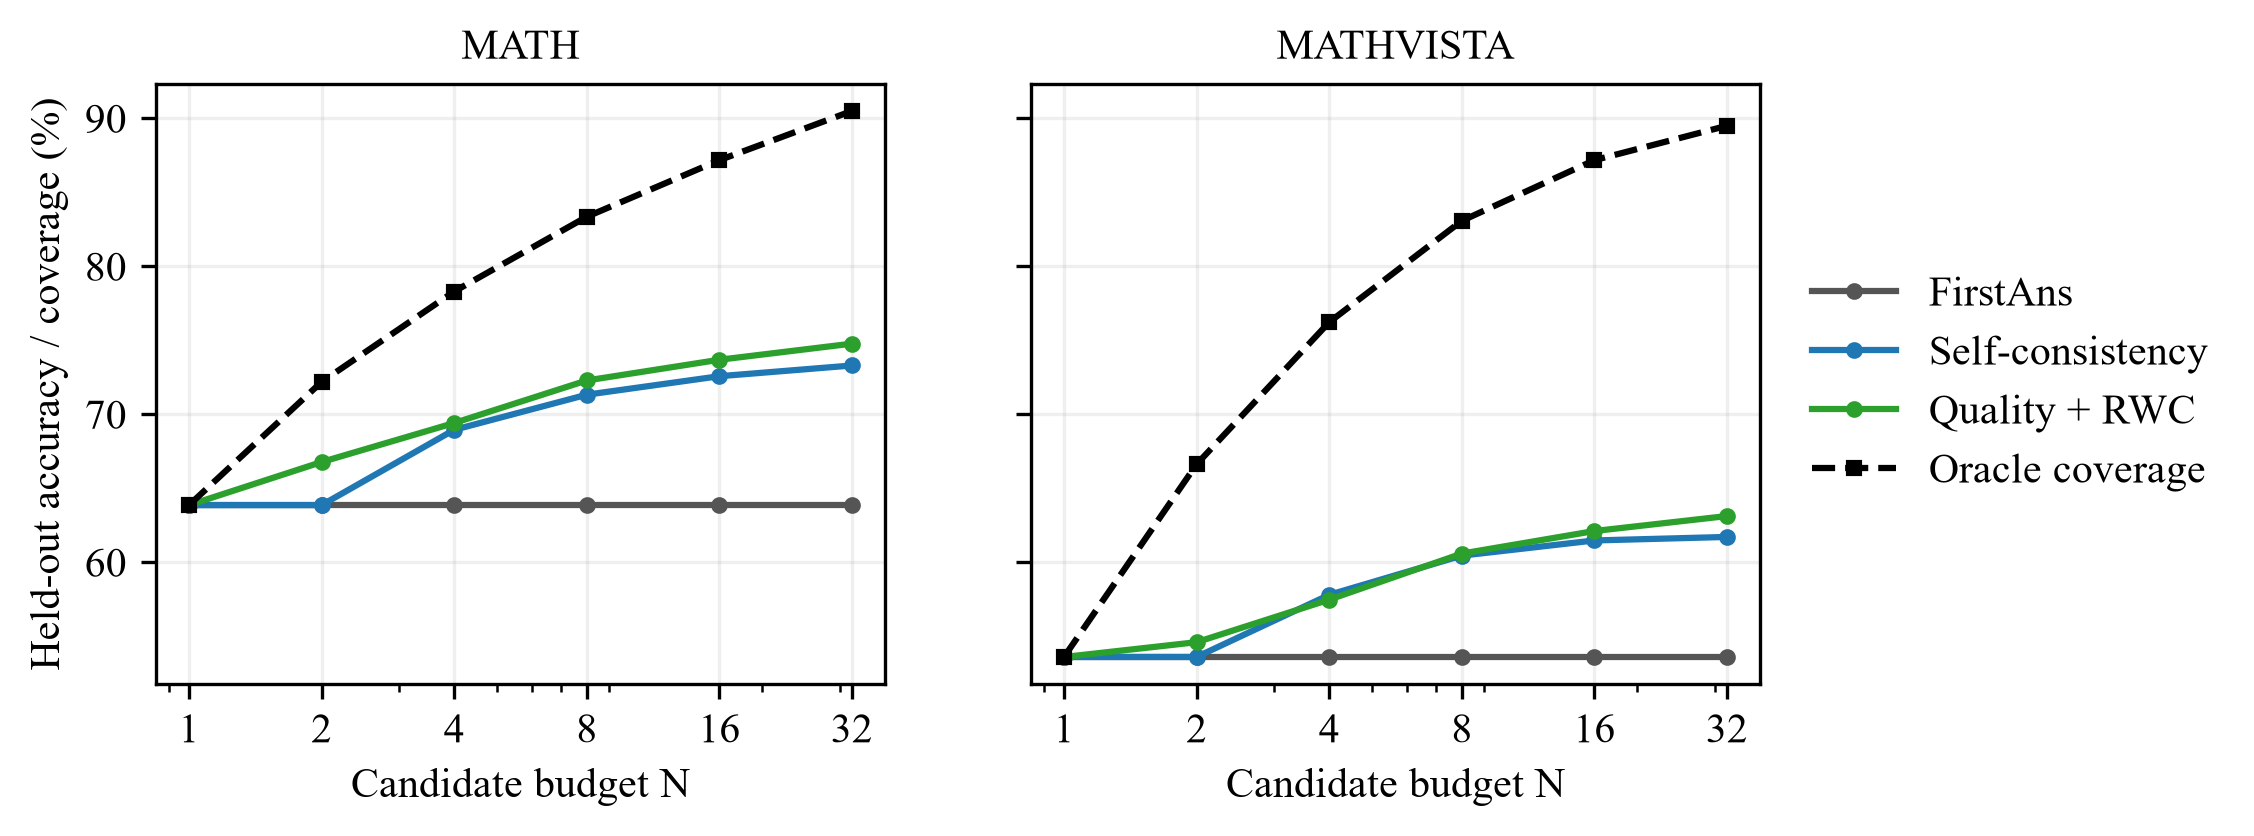

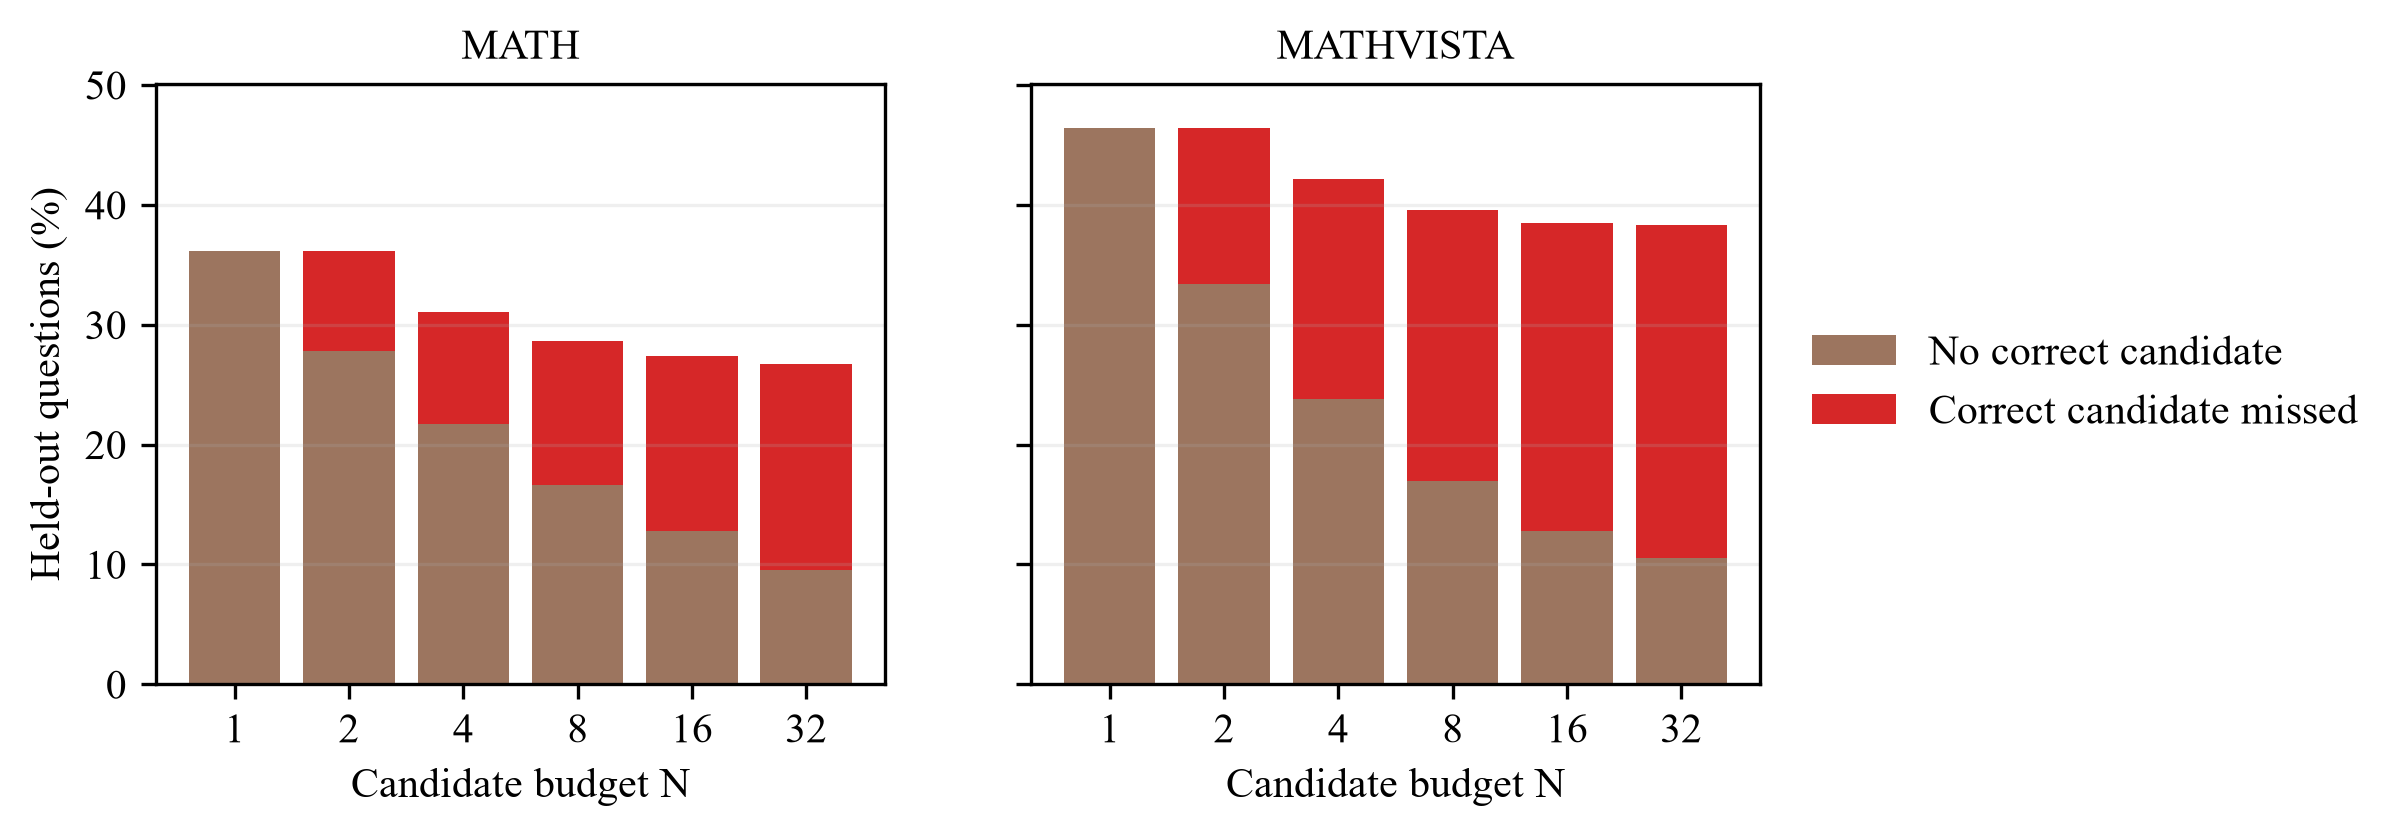

In [19]:
if EVIDENCE_READY:
    from analysis.evidence import rq1
    evidence_rq1 = rq1(results_root, regenerate_figures=RUN_COMPUTE)
    for dataset, table in evidence_rq1["tables"].items():
        print(dataset.upper(), "FirstAns, self-consistency, and quality selection")
        display(table)
    for dataset, table in evidence_rq1["methods_at_32"].items():
        print(dataset.upper(), "all methods at budget 32")
        display(table)
    for dataset, table in evidence_rq1["paired_intervals"].items():
        print(dataset.upper(), "paired intervals at budget 32")
        display(table.loc[table["budget"] == 32])
    print("Supplied export counts:", evidence_rq1["export_quality"])
    for path in evidence_rq1["figures"]:
        display(Image(filename=str(path)))

### RQ2: Evidence and consensus
Show score and correctness associations, confidence–vision relationships, and rollout versus tokenwise fusion.

MATH signal associations


,dataset_name,score,correctness_correlation,length_correlation,top_quartile_accuracy,bottom_quartile_accuracy,top_bottom_difference
0,math,certainty,0.198775,-0.161096,0.690156,0.570156,0.120000
1,math,length,-0.076418,1.000000,0.597969,0.642813,-0.044844
2,math,logp,0.135580,0.224510,0.672188,0.593125,0.079062


MATHVISTA signal associations


,dataset_name,score,correctness_correlation,length_correlation,top_quartile_accuracy,bottom_quartile_accuracy,top_bottom_difference
0,mathvista,certainty,0.047665,0.349333,0.549063,0.514219,0.034844
1,mathvista,confidence_vision_token_correlation,-0.210994,NaN,NaN,NaN,NaN
2,mathvista,length,-0.050391,1.000000,0.505000,0.545625,-0.040625
3,mathvista,logp,0.028683,0.328981,0.533125,0.517188,0.015938
4,mathvista,tokenwise,0.080468,-0.321803,0.561719,0.489531,0.072188
5,mathvista,visconf,0.088801,-0.275037,0.562500,0.488594,0.073906
6,mathvista,vision,0.041244,-0.685752,0.543125,0.505313,0.037812


,dataset_name,budget,method,correct,oracle,distinct_answers,token_cost,no_correct_candidate,selection_miss,questions
66,mathvista,32,tokenwise_best,0.56250,0.895,3.93875,8897.7575,0.105,0.33250,800
67,mathvista,32,tokenwise_rwc,0.62625,0.895,3.93875,8897.7575,0.105,0.26875,800
68,mathvista,32,visconf_best,0.57750,0.895,3.93875,8897.7575,0.105,0.31750,800
69,mathvista,32,visconf_rwc,0.63125,0.895,3.93875,8897.7575,0.105,0.26375,800
70,mathvista,32,vision_best,0.53625,0.895,3.93875,8897.7575,0.105,0.35875,800
71,mathvista,32,vision_rwc,0.62875,0.895,3.93875,8897.7575,0.105,0.26625,800


,mean
token_correlation,-0.210668
fusion_covariance,-0.002243


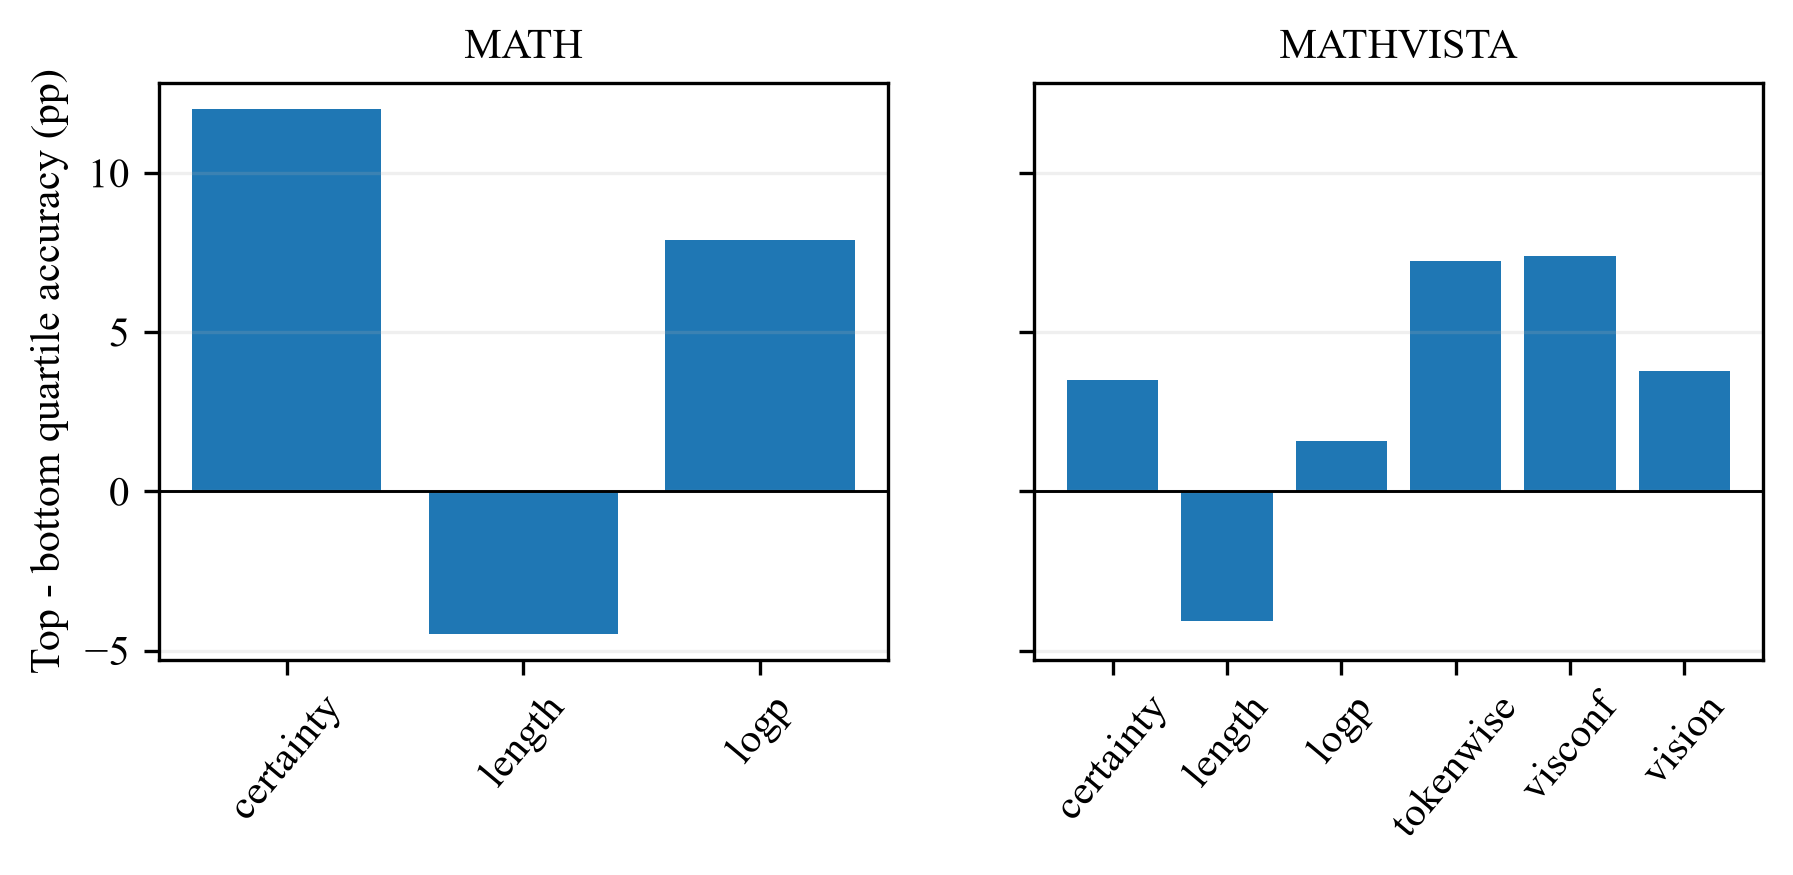

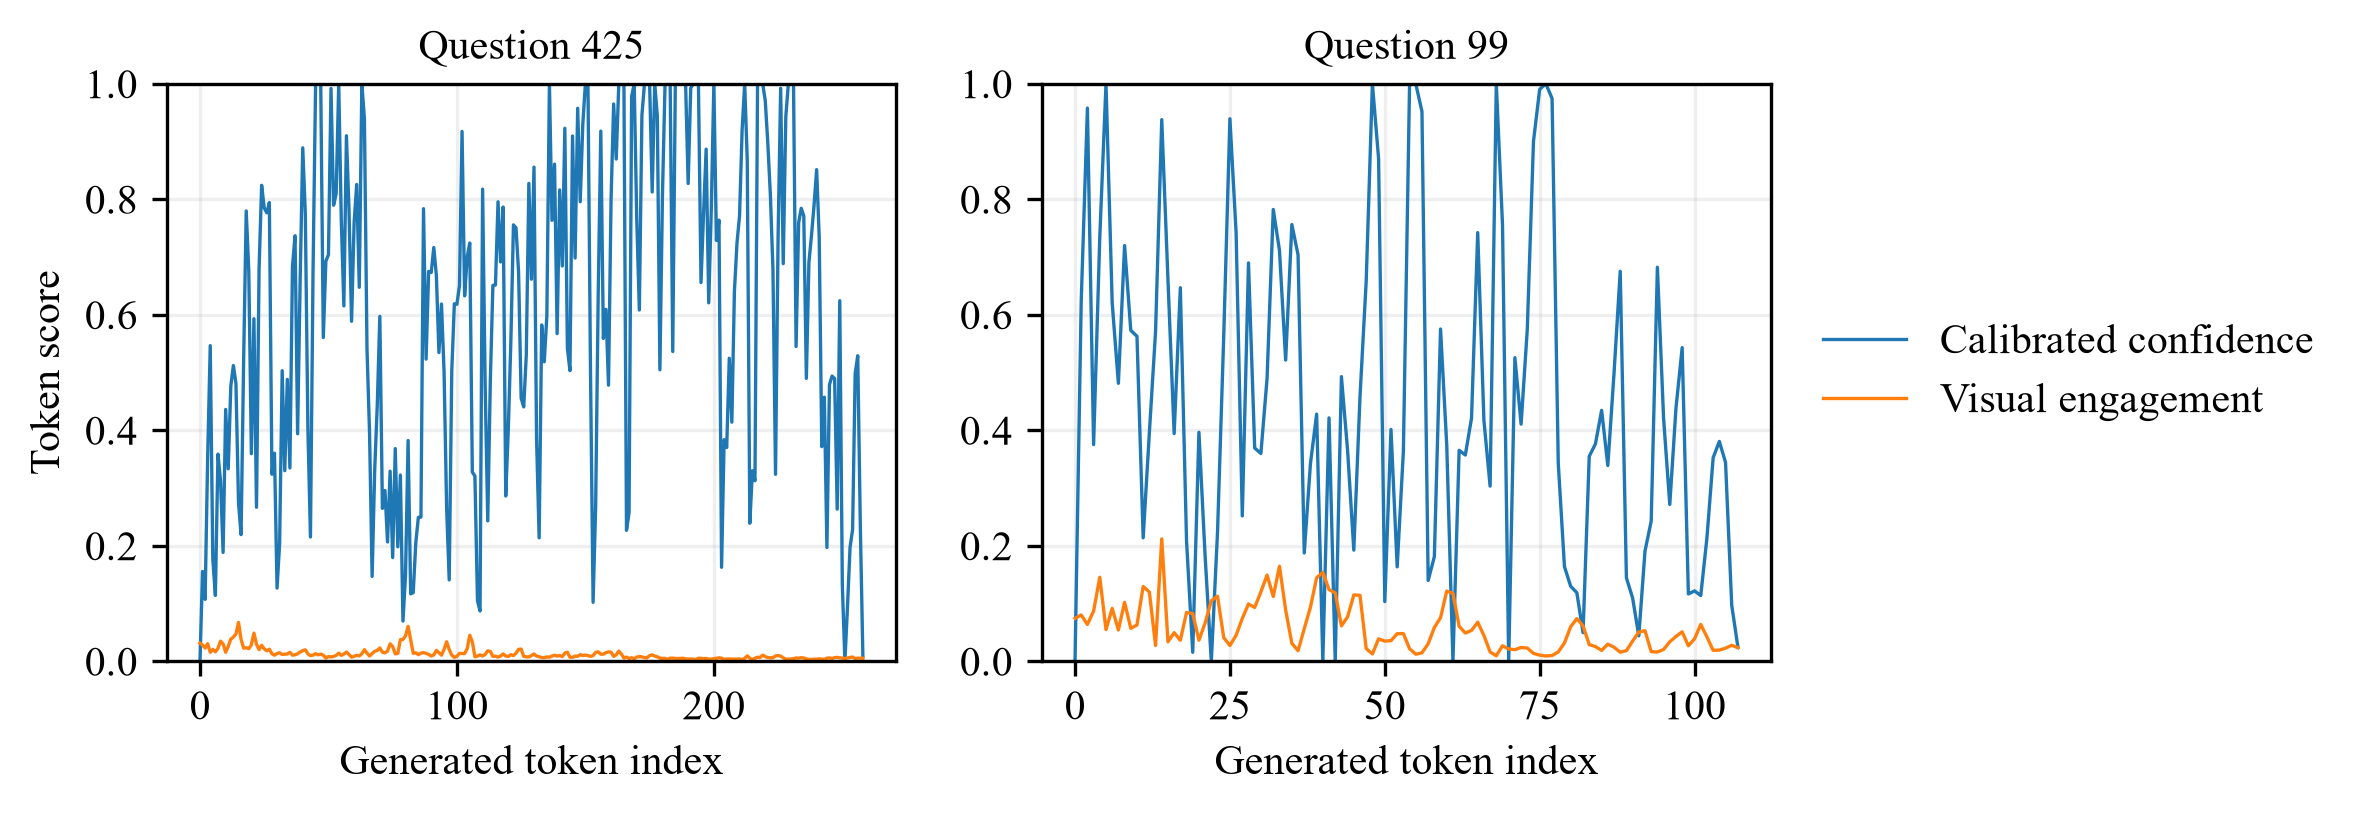

In [20]:
if EVIDENCE_READY:
    from analysis.evidence import rq2
    evidence_rq2 = rq2(results_root, regenerate_figures=RUN_COMPUTE)
    for dataset, table in evidence_rq2["signal_table"].items():
        print(dataset.upper(), "signal associations")
        display(table)
    display(evidence_rq2["fusion_table"])
    display(evidence_rq2["fusion_covariance"])
    for path in evidence_rq2["figures"]:
        display(Image(filename=str(path)))

### RQ3: Breadth and refinement
Compare the three live strategies on accuracy, input/output tokens, runtime, extraction, truncation, peak GPU memory, and revision transitions.

,strategy,accuracy,input_tokens,output_tokens,runtime_seconds,extraction_rate,truncation_rate,peak_gpu_gb,questions
0,parallel,0.58,325.14,1834.94,87.665298,0.86,0.26,5.946849,50
1,refinement,0.56,869.48,1209.84,58.707610,1.00,0.12,6.173303,50
2,single,0.72,108.38,736.30,35.751876,0.96,0.04,6.084351,50


,method,reference,difference_pp,ci_low_pp,ci_high_pp
0,parallel,single,-14.0,-26.0,-2.0
1,refinement,single,-16.0,-30.0,-2.0
2,refinement,parallel,-2.0,-10.0,6.0


{'wrong_to_correct': 0, 'correct_to_wrong': 0, 'initial_correct': 28, 'revised_correct': 28}


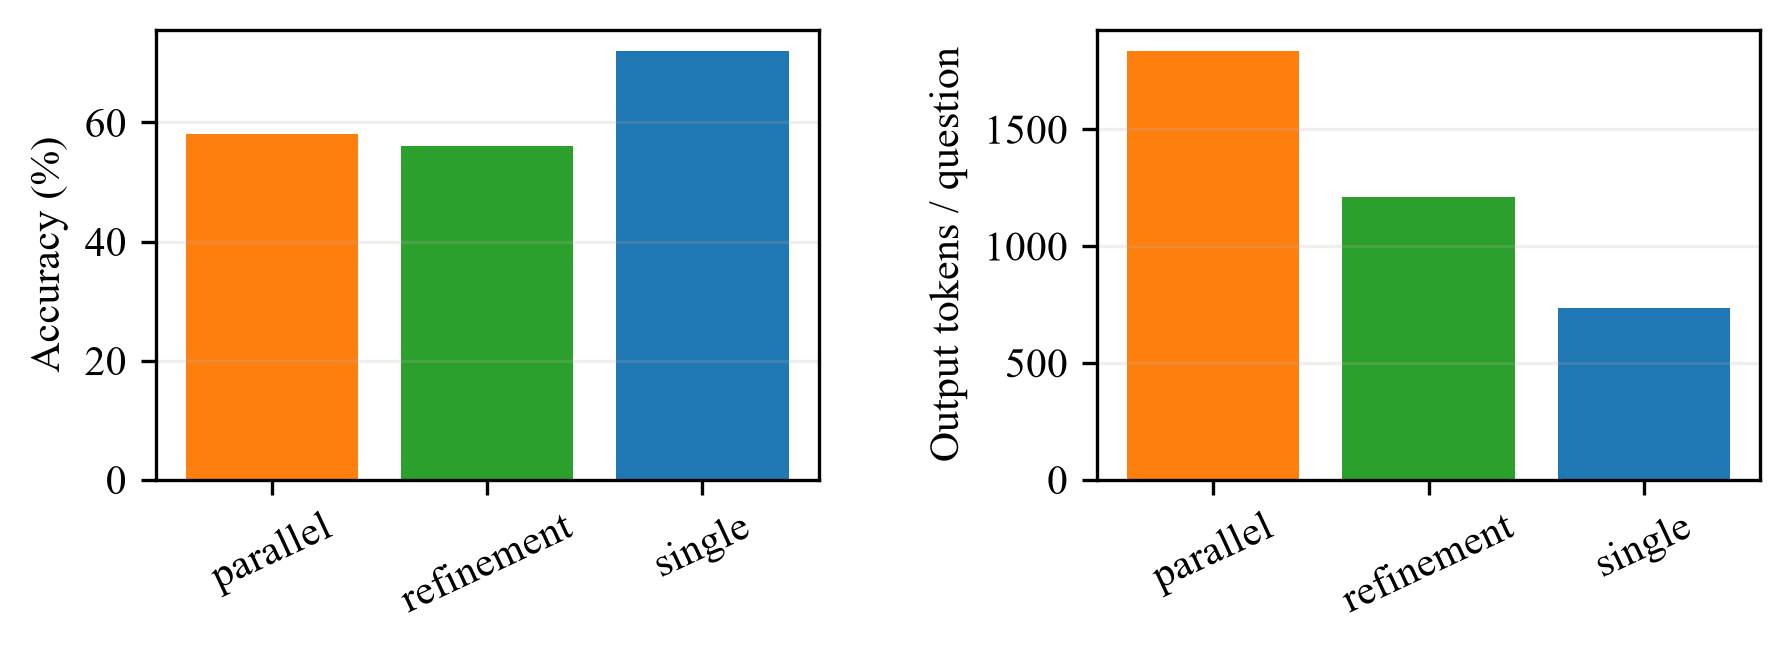

In [21]:
if EVIDENCE_READY:
    from analysis.evidence import rq3
    evidence_rq3 = rq3(results_root, regenerate_figures=RUN_COMPUTE)
    display(evidence_rq3["live_table"])
    display(evidence_rq3["paired_intervals"])
    print(evidence_rq3["revision_transitions"])
    for path in evidence_rq3["figures"]:
        display(Image(filename=str(path)))

### RQ4: Adaptive allocation
Show development-selected thresholds, held-out accuracy and cost, stopping distributions, and premature stops.

{'math': {'baseline_accuracy': 0.815, 'minimum_accuracy': 0.8049999999999999, 'agreement': {'family': 'agreement', 'tau': 0.5, 'gamma': None, 'accuracy': 0.809, 'mean_tokens': 4884.1985}, 'quality': {'family': 'quality', 'tau': 0.5, 'gamma': 0.0, 'accuracy': 0.8125, 'mean_tokens': 5260.075}}, 'mathvista': {'baseline_accuracy': 0.6425, 'minimum_accuracy': 0.6325, 'agreement': {'family': 'agreement', 'tau': 0.625, 'gamma': None, 'accuracy': 0.635, 'mean_tokens': 5285.1855}, 'quality': {'family': 'quality', 'tau': 0.5, 'gamma': 0.25, 'accuracy': 0.6325, 'mean_tokens': 4683.999}}}
MATH adaptive policy comparison


,dataset_name,policy,correct,token_cost,count,questions
0,math,agreement,0.723000,6750.029875,7.9380,800
1,math,always32,0.733000,21347.017500,32.0000,800
2,math,quality,0.727125,7622.621625,8.9165,800


MATHVISTA adaptive policy comparison


,dataset_name,policy,correct,token_cost,count,questions
0,mathvista,agreement,0.619500,4655.168125,13.7975,800
1,mathvista,always32,0.617125,8897.757500,32.0000,800
2,mathvista,quality,0.617750,4203.773625,12.8265,800


MATH paired policy intervals


,dataset_name,method,reference,difference_pp,ci_low_pp,ci_high_pp
0,math,agreement,always32,-1.0000,-1.725,-0.286875
1,math,quality,always32,-0.5875,-1.200,0.012500


... (6 outputs left out)

MATH stopping context


,dataset_name,policy,count,full_pool_bin,questions,accuracy,mean_agreement,mean_full_pool_correct_fraction
0,math,agreement,4,0-25%,200,0.065972,0.650391,0.076660
1,math,agreement,4,25-50%,77,0.691120,0.630309,0.407396
2,math,agreement,4,50-75%,74,0.951411,0.725313,0.664920
3,math,agreement,4,75-100%,432,0.998834,0.960529,0.958438
4,math,agreement,8,0-25%,64,0.033333,0.547222,0.088889
5,math,agreement,8,25-50%,50,0.670455,0.551136,0.408026
6,math,agreement,8,50-75%,50,0.945946,0.597973,0.646959
7,math,agreement,8,75-100%,28,1.000000,0.675781,0.827148
8,math,agreement,16,0-25%,20,0.000000,0.531250,0.062500
9,math,agreement,16,25-50%,21,0.636364,0.514205,0.417614


MATHVISTA stopping context


,dataset_name,policy,count,full_pool_bin,questions,accuracy,mean_agreement,mean_full_pool_correct_fraction
0,mathvista,agreement,4,0-25%,131,0.037244,0.837989,0.102945
1,mathvista,agreement,4,25-50%,130,0.524838,0.785097,0.401323
2,mathvista,agreement,4,50-75%,132,0.947160,0.819353,0.654929
3,mathvista,agreement,4,75-100%,292,0.998919,0.947046,0.930971
4,mathvista,agreement,8,0-25%,66,0.040984,0.656762,0.116803
5,mathvista,agreement,8,25-50%,88,0.580838,0.645958,0.412799
6,mathvista,agreement,8,50-75%,121,0.937729,0.657509,0.631181
7,mathvista,agreement,8,75-100%,81,1.000000,0.699803,0.840551
8,mathvista,agreement,16,0-25%,19,0.000000,0.652174,0.141304
9,mathvista,agreement,16,25-50%,17,0.450000,0.650000,0.415625


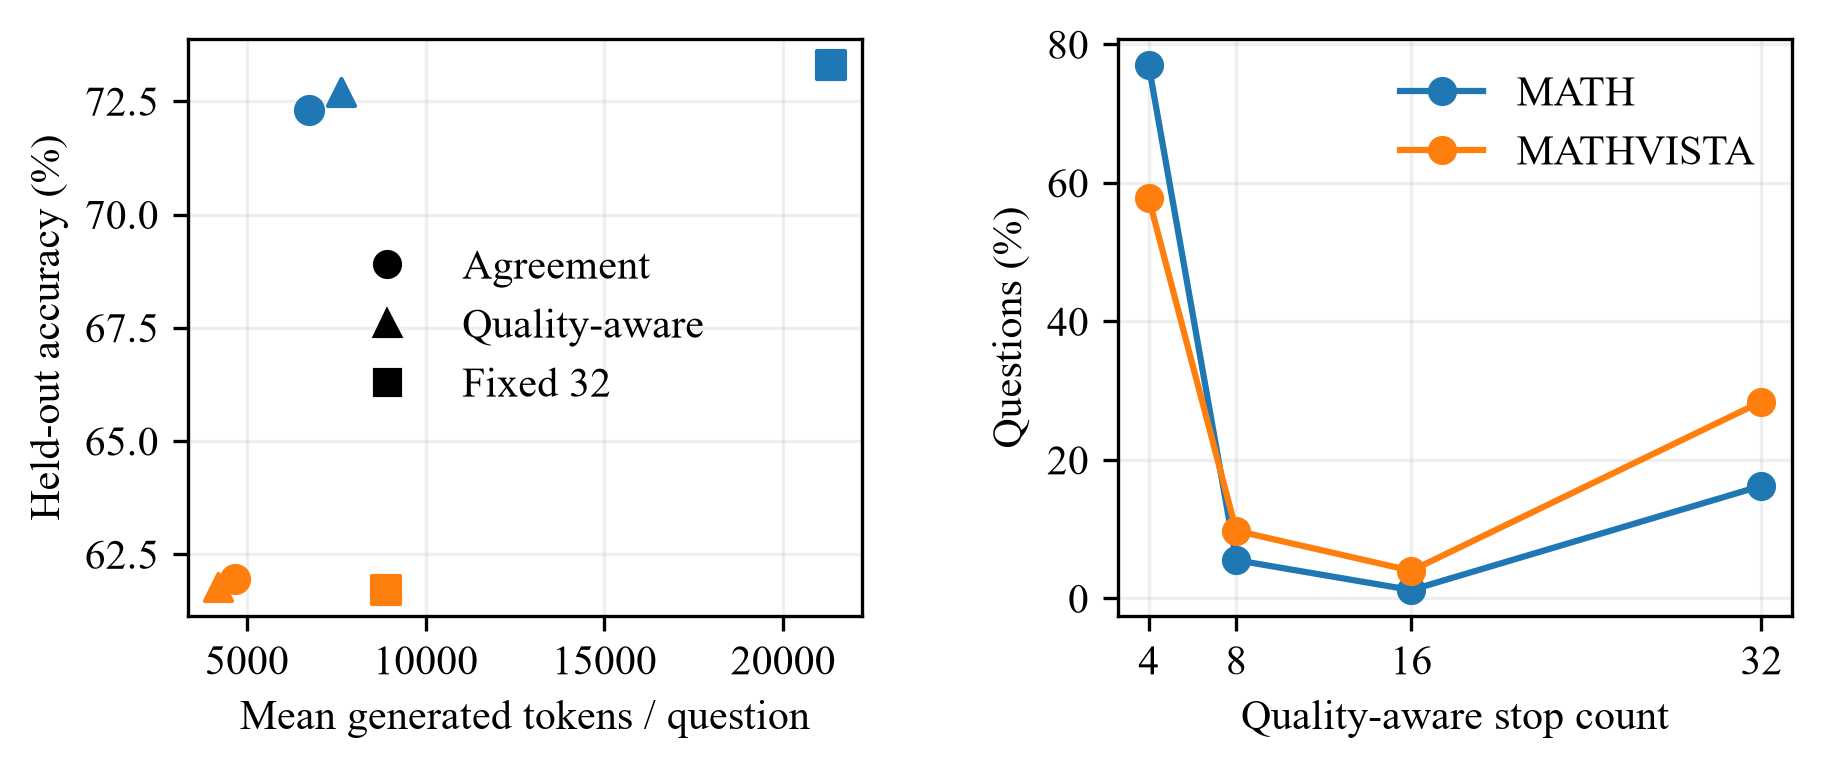

In [22]:
if EVIDENCE_READY:
    from analysis.evidence import rq4
    evidence_rq4 = rq4(results_root, regenerate_figures=RUN_COMPUTE)
    print(evidence_rq4["thresholds"])
    for dataset, table in evidence_rq4["adaptive_table"].items():
        print(dataset.upper(), "adaptive policy comparison")
        display(table)
    for dataset, table in evidence_rq4["paired_intervals"].items():
        print(dataset.upper(), "paired policy intervals")
        display(table)
    for dataset, table in evidence_rq4["stopping_distributions"].items():
        print(dataset.upper(), "stopping distribution")
        display(table)
    for dataset, table in evidence_rq4["stopping_context"].items():
        print(dataset.upper(), "stopping context")
        display(table)
    for path in evidence_rq4["figures"]:
        display(Image(filename=str(path)))

### RQ5: Compute and reliability
Compare accuracy against generated-token cost and inspect reproducibly selected selection, revision, and premature-stop cases.

MATH accuracy, compute cost, and candidate count


,dataset_name,policy,correct,token_cost,count,questions
0,math,agreement,0.723000,6750.029875,7.9380,800
1,math,always32,0.733000,21347.017500,32.0000,800
2,math,quality,0.727125,7622.621625,8.9165,800


MATHVISTA accuracy, compute cost, and candidate count


,dataset_name,policy,correct,token_cost,count,questions
0,mathvista,agreement,0.619500,4655.168125,13.7975,800
1,mathvista,always32,0.617125,8897.757500,32.0000,800
2,mathvista,quality,0.617750,4203.773625,12.8265,800


Aligned example IDs and selection rules:
math_selection_disagreement test:1787 Lexicographically first held-out question, order 0, N=32, with a correctness disagreement
math_premature_stop test:1157 Lexicographically first held-out quality-aware early error recovered at fixed 32
mathvista_selection_disagreement 10 Lexicographically first held-out question, order 0, N=32, with a correctness disagreement
mathvista_premature_stop 120 Lexicographically first held-out quality-aware early error recovered at fixed 32
revision_changed_answer test:2177 First sample ID whose extracted answer changed in revision


,case,sample_id,question,gold,method,answer,correct,response_excerpt
0,math_selection_disagreement,test:1787,A pyramid has 6 vertices and 6 faces. How many...,10\;\text{edges},self_consistency,12,False,To determine the number of edges in a pyramid ...
1,math_selection_disagreement,test:1787,A pyramid has 6 vertices and 6 faces. How many...,10\;\text{edges},certainty_rwc,10,True,To determine the number of edges in a pyramid ...
2,math_premature_stop,test:1157,Suppose we define $\ell(n)$ as follows: If $n$...,14,early stop,15,NaN,To determine how many numbers are in the domai...
3,math_premature_stop,test:1157,Suppose we define $\ell(n)$ as follows: If $n$...,14,fixed 32,14,NaN,To determine how many numbers are in the domai...
4,mathvista_selection_disagreement,10,Which object comes next?\nA. A\nB. B\nC. C\nD....,E,self_consistency,NaN,False,"To determine which object comes next, let's an..."
5,mathvista_selection_disagreement,10,Which object comes next?\nA. A\nB. B\nC. C\nD....,E,visconf_rwc,E,True,"To determine which object comes next, we need ..."
6,mathvista_premature_stop,120,What is the degree of this function?,3,early stop,2,NaN,"To determine the degree of the function, we ne..."
7,mathvista_premature_stop,120,What is the degree of this function?,3,fixed 32,3,NaN,"To determine the degree of the function, we ne..."
8,revision_changed_answer,test:2177,"Let $(a_1,b_1),$ $(a_2,b_2),$ $\dots,$ $(a_n,b...",18,initial,NaN,NaN,To solve the given system of equations for the...
9,revision_changed_answer,test:2177,"Let $(a_1,b_1),$ $(a_2,b_2),$ $\dots,$ $(a_n,b...",18,revision,10,NaN,Let's carefully review the solution and correc...


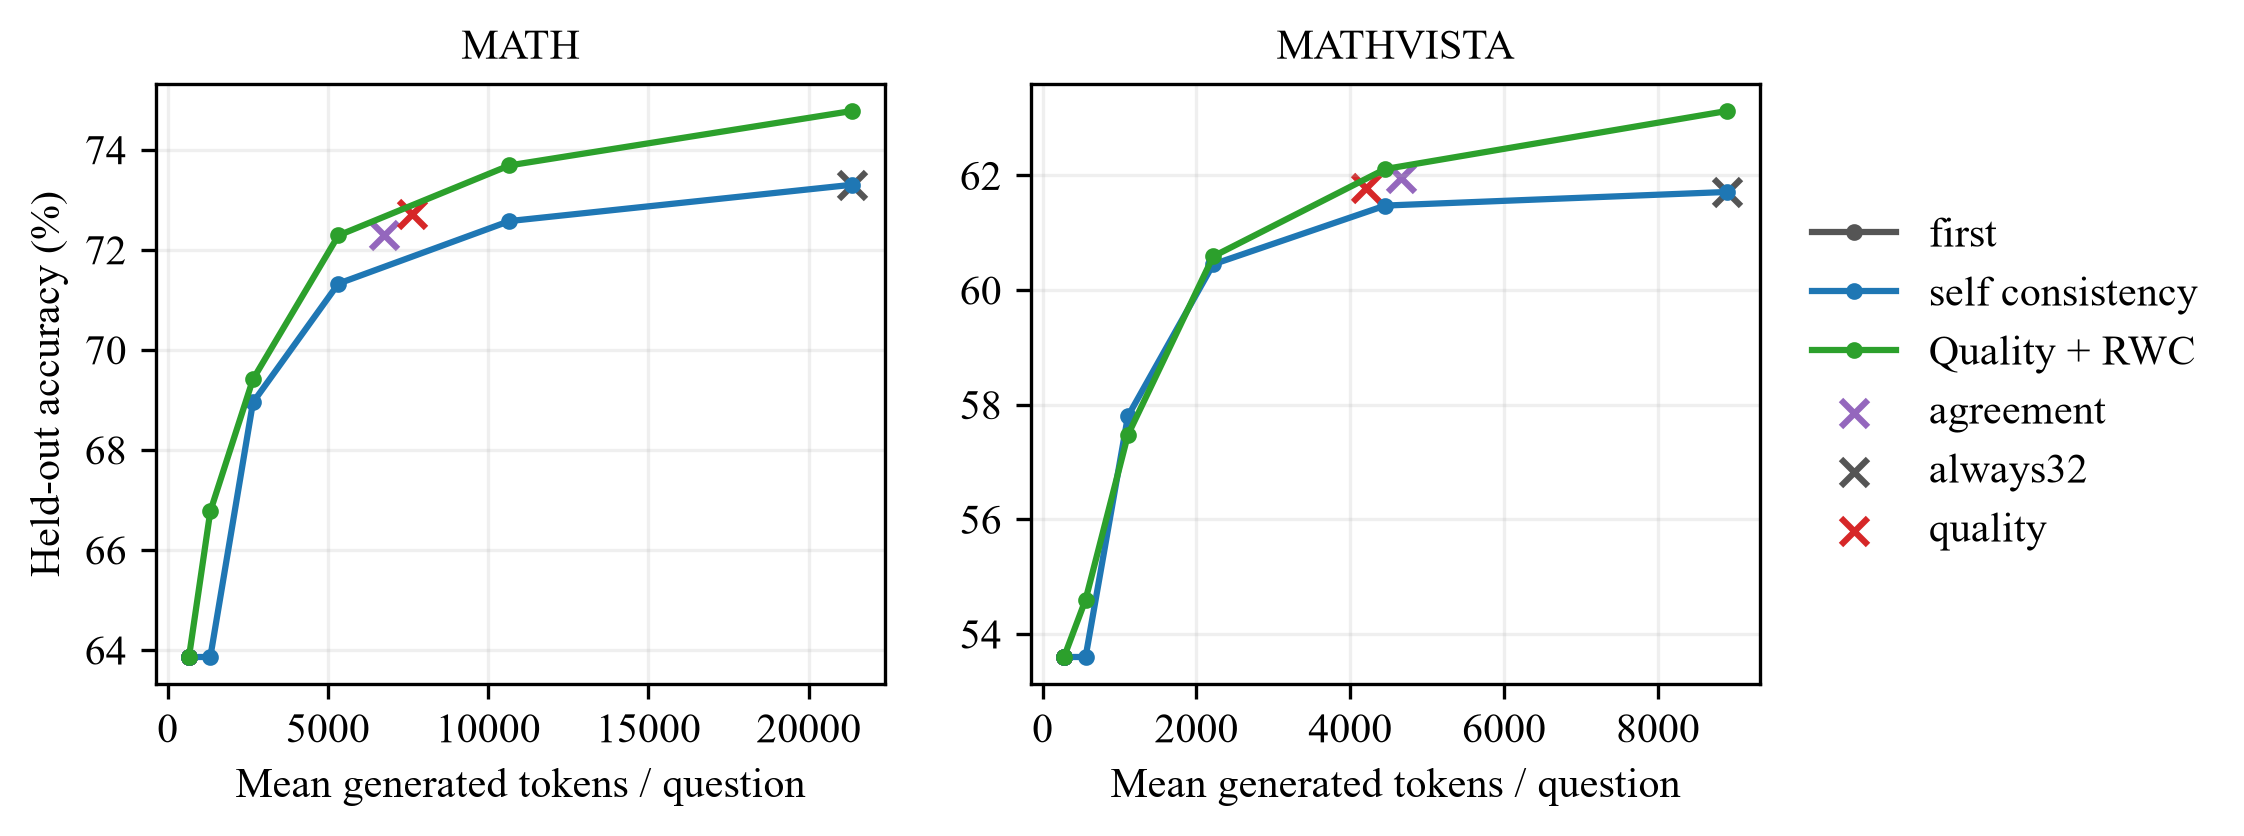

In [23]:
if EVIDENCE_READY:
    from analysis.evidence import rq5
    evidence_rq5 = rq5(results_root, regenerate_figures=RUN_COMPUTE)
    for dataset, table in evidence_rq5["cost_tables"].items():
        print(dataset.upper(), "accuracy, compute cost, and candidate count")
        display(table)
    print("Aligned example IDs and selection rules:")
    for name, example in evidence_rq5["examples"].items():
        print(name, example["sample_id"], example["rule"])
    display(evidence_rq5["example_table"])
    for path in evidence_rq5["figures"]:
        display(Image(filename=str(path)))